# S7 · Main regression framework and results

The model of Table 1, now shown across five sets of fixed effects, from
none to the preferred one (sender + classroom-by-round). Column (5) of
each table is the corresponding column of Table 1. Code:
`code/si/S7_main_regressions.R` and the helper `fe_progression()` in
`code/00_helpers.R`. (The wild-cluster bootstrap takes about a minute.)

In [ ]:
here::i_am("notebooks/si/S7_main_regressions.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads <- read_csv(here("data", "generated", "analysis_dyads.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

# Linear combination of coefficients (estimate and clustered SE), e.g. the
# implied mutual-friend slope = rank_gap + rank_gap:mutual
linear_combination <- function(model, terms) {
  b <- coef(model); V <- vcov(model)
  w <- setNames(rep(0, length(b)), names(b)); w[terms] <- 1
  c(estimate = sum(w * b), se = sqrt(drop(t(w) %*% V %*% w)))
}

## Tables S17–S19. Observed Cooperation GAP by friendship group

Each table fits the same five specifications to a different sample.
Standard errors are in parentheses.

### Table S17. All dyads

In [ ]:
# Tables S17-S19: the five specifications for three samples
fe_all    <- fe_progression(dyads)
fe_non    <- fe_progression(filter(dyads, friendship == "Non-friends"))
fe_mutual <- fe_progression(filter(dyads, friendship == "Mutual"))

regression_table(fe_all,    terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,2.584***,2.584***,2.587***,2.587***,2.584***
,(0.098),(0.272),(0.272),(0.272),(0.274)
Observations,"17,804","17,804","17,804","17,804","17,804"
R2,0.037,0.037,0.271,0.271,0.275
Adj. R2,0.037,0.035,0.234,0.232,0.189


### Table S18. Non-friends

In [ ]:
regression_table(fe_non,    terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,2.574***,2.574***,2.573***,2.574***,2.562***
,(0.110),(0.264),(0.272),(0.272),(0.281)
Observations,"13,916","13,916","13,916","13,916","13,916"
R2,0.038,0.038,0.286,0.286,0.297
Adj. R2,0.038,0.035,0.239,0.237,0.187


### Table S19. Mutual friends

In [ ]:
regression_table(fe_mutual, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,0.293,0.293,1.254,1.265†,1.069
,(0.403),(0.693),(0.780),(0.718),(1.327)
Observations,"1,288","1,288","1,288","1,288","1,288"
R2,0.000,0.000,0.645,0.658,0.839
Adj. R2,-0.000,-0.036,0.277,0.259,0.077


## Table S20. Pooled friendship moderation

### Pooled model with the friendship interaction

This model estimates how the Social Rank GAP slope differs between
non-friends and mutual friends.

In [ ]:
# Table S20: non-friends and mutual friends together, rank gap x mutual
non_and_mutual <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual")) %>%
  mutate(mutual = as.integer(friendship == "Mutual"))

fe_pooled <- fe_progression(non_and_mutual, formula_rhs = "rank_gap * mutual")

regression_table(fe_pooled, terms = c("rank_gap", "mutual", "rank_gap:mutual"))

row,(1),(2),(3),(4),(5)
rank_gap,2.574***,2.574***,2.583***,2.582***,2.592***
,(0.109),(0.264),(0.262),(0.261),(0.267)
mutual,-0.000,-0.000,-0.059,-0.061,-0.030
,(0.135),(0.000),(0.077),(0.076),(0.091)
rank_gap:mutual,-2.281***,-2.281***,-1.707**,-1.706**,-1.674**
,(0.453),(0.611),(0.553),(0.553),(0.557)
Observations,"15,204","15,204","15,204","15,204","15,204"
R2,0.035,0.035,0.275,0.275,0.283
Adj. R2,0.035,0.032,0.232,0.230,0.181


### Implied slope for mutual friends

This combines the Social Rank GAP coefficient and the interaction
coefficient within each model.

In [ ]:
implied_mutual_slope <- map_dfr(fe_pooled, ~ linear_combination(.x, c("rank_gap", "rank_gap:mutual")),
                                .id = "model")
implied_mutual_slope

model,estimate,se
(1),0.2929030,0.4392462
(2),0.2929030,0.6924580
(3),0.8759189,0.6437706
(4),0.8761405,0.6442929
(5),0.9188269,0.6541811


## Table S21. Support for the two asymmetric directions

In [ ]:
# Table S21: one-sided friendships seen from the child who named the other.
# L->H when she has the lower rank (gap < 0), H->L otherwise (ties to H->L,
# as in Table 1).
asymmetric <- dyads %>%
  filter(friendship == "Sender declares") %>%
  mutate(direction = if_else(rank_gap < 0, "L->H", "H->L"),
         high_to_low = as.integer(direction == "H->L"))

sender_support <- asymmetric %>%
  group_by(class_id, sender_id) %>%
  summarise(n_lh = sum(direction == "L->H"), n_hl = sum(direction == "H->L"), .groups = "drop") %>%
  mutate(support = case_when(n_lh > 0 & n_hl > 0 ~ "Both L->H and H->L",
                             n_lh > 0            ~ "Only L->H",
                             TRUE                ~ "Only H->L"))

support_row <- function(units, label) {
  rows <- asymmetric %>% semi_join(units, by = "sender_id")
  tibble(support = label, sender_class_units = nrow(units), observations = nrow(rows),
         classrooms = n_distinct(rows$class_id),
         lh_obs = sum(rows$direction == "L->H"), hl_obs = sum(rows$direction == "H->L"))
}

table_s21 <- bind_rows(
  map_dfr(c("Both L->H and H->L", "Only L->H", "Only H->L"),
          ~ support_row(filter(sender_support, support == .x), .x)),
  support_row(sender_support, "Total asymmetric sample"),
  support_row(filter(sender_support, n_lh >= 2, n_hl >= 2), "Sender with >=2 L->H and >=2 H->L")
)

table_s21

support,sender_class_units,observations,classrooms,lh_obs,hl_obs
Both L->H and H->L,148,418,41,226,192
Only L->H,351,668,45,668,0
Only H->L,156,214,43,0,214
Total asymmetric sample,655,1300,45,894,406
Sender with >=2 L->H and >=2 H->L,11,47,7,23,24


## Table S22. Asymmetric friendships by direction

### Lower to higher rank

The child making the nomination has the lower Social Rank.

In [ ]:
# Table S22: the five specifications for each direction separately
fe_low_to_high <- fe_progression(filter(asymmetric, direction == "L->H"))
fe_high_to_low <- fe_progression(filter(asymmetric, direction == "H->L"))

regression_table(fe_low_to_high, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,2.586***,2.638***,3.066**,3.056*,-1.154
,(0.708),(0.708),(1.105),(1.182),(4.173)
Observations,894,894,894,894,894
R2,0.015,0.075,0.672,0.724,0.985
Adj. R2,0.014,0.026,0.256,0.299,0.435


### Higher to lower rank

This group follows Table 1’s rule and includes ties in Social Rank.

In [ ]:
regression_table(fe_high_to_low, terms = "rank_gap")

row,(1),(2),(3),(4),(5)
rank_gap,-0.536,0.208,3.520,4.767,-33.862
,(1.326),(1.489),(3.667),(3.487),(8.177)
Observations,406,406,406,406,406
R2,0.000,0.131,0.838,0.897,1.000
Adj. R2,-0.002,0.023,0.352,0.324,0.896


## Table S23. Direct contrast between the two directions

In [ ]:
# Table S23: one pooled model for both directions,
#   Coop GAP = b_LH RankGAP + theta HL + b_delta (RankGAP x HL) + FE
# b_delta is the direct test of whether the two slopes differ.
# All columns cluster by classroom (also column 1 here). CIs use t(44).
contrast_formula <- function(fixed_effects) {
  as.formula(paste("coop_gap ~ rank_gap * high_to_low |", fixed_effects, "| 0 | class_id"))
}

contrast_specs <- c("(1)" = "0", "(2)" = "class_id", "(3)" = "class_id + sender_id",
                    "(4)" = "class_id + sender_id + round", "(5)" = "sender_id + class_round")

asymmetric <- asymmetric %>%
  mutate(class_round = paste(class_id, round, sep = "_"),
         across(c(sender_id, class_id, class_round, round), as.factor, .names = "{.col}"))

contrast_models <- map(contrast_specs, ~ felm(contrast_formula(.x), data = asymmetric))

In [ ]:
# Wild-cluster bootstrap p-value for the interaction (restricted, Rademacher
# weights by classroom, 999 draws): impose b_delta = 0, flip the sign of the
# residuals of whole classrooms at random, re-estimate, and compare t-values.
wild_cluster_p <- function(fixed_effects, draws = 999, seed = 123) {
  full       <- felm(contrast_formula(fixed_effects), data = asymmetric)
  t_observed <- summary(full)$coefficients["rank_gap:high_to_low", "t value"]

  restricted <- felm(as.formula(paste("coop_gap ~ rank_gap + high_to_low |", fixed_effects,
                                      "| 0 | class_id")), data = asymmetric)
  fitted_r   <- asymmetric$coop_gap - residuals(restricted)[, 1]
  resid_r    <- residuals(restricted)[, 1]
  classes    <- unique(asymmetric$class_id)

  set.seed(seed)
  t_star <- map_dbl(1:draws, function(b) {
    sign_by_class <- setNames(sample(c(-1, 1), length(classes), replace = TRUE), classes)
    boot_data <- asymmetric %>%
      mutate(coop_gap = fitted_r + resid_r * sign_by_class[as.character(class_id)])
    summary(felm(contrast_formula(fixed_effects), data = boot_data))$coefficients["rank_gap:high_to_low", "t value"]
  })
  mean(abs(t_star) >= abs(t_observed))
}

table_s23 <- imap_dfr(contrast_models, function(fit, name) {
  ct <- summary(fit)$coefficients
  ix <- ct["rank_gap:high_to_low", ]
  t_crit <- qt(0.975, df = 44)
  tibble(model = name,
         slope_lh = ct["rank_gap", "Estimate"], se_lh = ct["rank_gap", "Cluster s.e."],
         slope_hl = linear_combination(fit, c("rank_gap", "rank_gap:high_to_low"))[["estimate"]],
         se_hl    = linear_combination(fit, c("rank_gap", "rank_gap:high_to_low"))[["se"]],
         interaction = ix[["Estimate"]], se_interaction = ix[["Cluster s.e."]],
         ci_low  = ix[["Estimate"]] - t_crit * ix[["Cluster s.e."]],
         ci_high = ix[["Estimate"]] + t_crit * ix[["Cluster s.e."]],
         cluster_p = 2 * pt(-abs(ix[["t value"]]), df = 44),
         wild_cluster_p = wild_cluster_p(contrast_specs[[name]]))
})

table_s23 %>% mutate(across(where(is.double), ~ round(.x, 3)))

model,slope_lh,se_lh,slope_hl,se_hl,interaction,se_interaction,ci_low,ci_high,cluster_p,wild_cluster_p
(1),2.586,0.705,-0.536,1.410,-3.122,1.597,-6.341,0.097,0.057,0.069
(2),2.685,0.709,-0.680,1.433,-3.365,1.604,-6.598,-0.131,0.042,0.051
(3),2.897,1.148,2.271,2.761,-0.626,2.496,-5.657,4.404,0.803,0.832
(4),2.687,1.175,2.454,2.777,-0.233,2.682,-5.638,5.173,0.931,0.927
(5),-5.243,2.691,1.064,5.860,6.306,4.780,-3.326,15.939,0.194,0.151


## Table S24 and Figures S22–S24. Size of the effect

### Table S24. Predicted gaps at selected rank differences

In [ ]:
# Table S24: the main coefficient times the rank gaps that actually occur
beta_main <- coef(fe_all[["(5)"]])[["rank_gap"]]
abs_gap <- abs(dyads$rank_gap)

table_s24 <- tibble(
  contrast  = c("Median dyad", "75th pct", "90th pct", "95th pct", "99th pct", "Full unit"),
  gap_value = c(quantile(abs_gap, c(0.50, 0.75, 0.90, 0.95, 0.99)), 1),
  share_at_least = map_dbl(gap_value, ~ 100 * mean(abs_gap >= .x - 1e-9)),
  predicted_coop_gap = beta_main * gap_value
)
table_s24

contrast,gap_value,share_at_least,predicted_coop_gap
Median dyad,0.2210636,50.0000000,0.5712187
75th pct,0.4034816,25.0056167,1.0425791
90th pct,0.6039060,10.0089867,1.5604670
95th pct,0.7185979,5.0101101,1.8568259
99th pct,0.9289566,1.0110088,2.4003836
Full unit,1.0000000,0.5055044,2.5839567


### Share of decisions by distance between rank quartiles

In [ ]:
# Rank quartiles (cut points over all senders and receivers) and the
# distance between the sender's and receiver's quartiles
quartile_cuts <- quantile(c(dyads$sender_rank, dyads$receiver_rank), c(0.25, 0.5, 0.75))
quartiled <- dyads %>%
  mutate(sender_q   = findInterval(sender_rank,   quartile_cuts, left.open = TRUE) + 1,
         receiver_q = findInterval(receiver_rank, quartile_cuts, left.open = TRUE) + 1,
         distance   = abs(sender_q - receiver_q))

# average over classrooms of the share at each quartile distance
quartiled %>%
  group_by(class_id) %>%
  count(distance) %>% mutate(share = 100 * n / sum(n)) %>%
  group_by(distance) %>% summarise(mean_share = mean(share))

distance,mean_share
0,28.91612
1,37.20094
2,20.58494
3,13.29799


### Share of decisions across different quartiles, by classroom

In [ ]:
quartiled %>% group_by(class_id) %>% summarise(cross = 100 * mean(distance > 0)) %>%
  summarise(mean = mean(cross), min = min(cross), max = max(cross))

mean,min,max
71.08388,54.54545,80.95238


### Decisions from the highest to the lowest quartile

The observed mean Cooperation GAP is shown alongside the value predicted
by the main coefficient.

In [ ]:
quartile_cells <- quartiled %>%
  group_by(sender_q, receiver_q) %>%
  summarise(n = n(), mean_gap = mean(rank_gap), observed = mean(coop_gap), .groups = "drop") %>%
  mutate(predicted = beta_main * mean_gap, share = 100 * n / sum(n))
quartile_cells %>% filter(sender_q == 4, receiver_q == 1)

sender_q,receiver_q,n,mean_gap,observed,predicted,share
4,1,1002,0.6805491,1.541916,1.758509,5.627949


In [ ]:
# Figure S22: distribution of the Social Rank GAP, with lines at the 90th
# percentile of |GAP| and at the extreme top-vs-bottom contrast
p90 <- quantile(abs_gap, 0.9)
reference_lines <- tibble(x = c(-p90, p90, -1, 1),
                          kind = rep(c(sprintf("90th pct |GAP| = %.2f", p90),
                                       "\u00b11 (extreme top-vs-bottom)"), each = 2))

The figure as in the SI, with its colors, labels and legends (code from
the script):

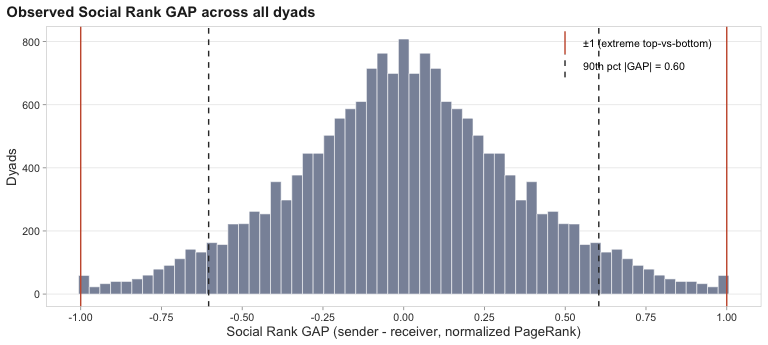

In [ ]:
figure_s22 <- ggplot(dyads, aes(rank_gap)) +
  geom_histogram(binwidth = 0.033, fill = color_slate, color = "white", linewidth = 0.2) +
  geom_vline(data = reference_lines, aes(xintercept = x, color = kind, linetype = kind)) +
  # The 90th-percentile lines in orange, the extreme ones dashed
  scale_color_manual(values = c(color_highlight, "grey20"), name = NULL) +
  scale_linetype_manual(values = c("solid", "dashed"), name = NULL) +
  scale_x_continuous(breaks = seq(-1, 1, 0.25)) +
  labs(title = "Observed Social Rank GAP across all dyads",
       x = "Social Rank GAP (sender - receiver, normalized PageRank)", y = "Dyads") +
  theme_si(10) + theme(legend.position = c(0.82, 0.9))
figure_s22

In [ ]:
# Figure S23: binned means and the linear prediction over the whole range,
# with the central 50%, 80% and 90% of dyads shaded
binned <- dyads %>%
  mutate(bin = ntile(rank_gap, 20)) %>%
  group_by(bin) %>%
  summarise(gap = mean(rank_gap), mean = mean(coop_gap), se = sd(coop_gap) / sqrt(n()))

bands <- tibble(share = c("90% of dyads", "80% of dyads", "50% of dyads"),
                low   = quantile(dyads$rank_gap, c(0.05, 0.10, 0.25)),
                high  = quantile(dyads$rank_gap, c(0.95, 0.90, 0.75))) %>%
  mutate(share = factor(share, levels = c("50% of dyads", "80% of dyads", "90% of dyads")))

The figure as in the SI, with its colors, labels and legends (code from
the script):

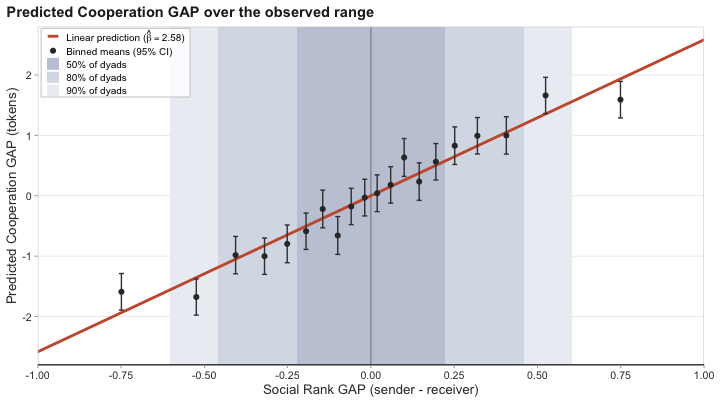

In [ ]:
figure_s23 <- ggplot() +
  geom_rect(data = bands, aes(xmin = low, xmax = high, ymin = -Inf, ymax = Inf, fill = share)) +
  geom_vline(xintercept = 0, color = "grey45", linewidth = 0.3) +
  geom_abline(aes(slope = beta_main, intercept = 0, linetype = "prediction"),
              color = color_highlight, linewidth = 1, key_glyph = "path") +
  geom_errorbar(data = binned, aes(gap, ymin = mean - 1.96 * se, ymax = mean + 1.96 * se),
                width = 0.015, color = "grey25") +
  geom_point(data = binned, aes(gap, mean, shape = "Binned means (95% CI)"), color = "grey20", size = 1.8) +
  # Gray shades for the bands, the slope written as beta-hat in
  # the legend, the axes cut at -1 and 1
  scale_fill_manual(values = c("50% of dyads" = "#C3CAD8", "80% of dyads" = "#D9DEE7",
                               "90% of dyads" = "#ECEEF3"), name = NULL) +
  scale_linetype_manual(values = "solid", name = NULL,
                        labels = as.expression(list(
                          bquote("Linear prediction (" * hat(beta) == .(sprintf("%.2f", beta_main)) * ")")))) +
  scale_shape_manual(values = 16, name = NULL) +
  scale_x_continuous(breaks = seq(-1, 1, 0.25), labels = function(x) sprintf("%.2f", x)) +
  scale_y_continuous(breaks = -2:2) +
  coord_cartesian(xlim = c(-1, 1), ylim = c(-2.8, 2.8), expand = FALSE) +
  labs(title = "Predicted Cooperation GAP over the observed range",
       x = "Social Rank GAP (sender - receiver)", y = "Predicted Cooperation GAP (tokens)") +
  theme_si(10) +
  theme(legend.position = c(0.005, 0.995), legend.justification = c(0, 1),
        legend.spacing.y = unit(0, "mm"), legend.key.size = unit(3.5, "mm"),
        legend.text = element_text(size = 7.5),
        legend.background = element_blank(), legend.margin = margin(0, 4, 0, 4),
        legend.box.background = element_rect(fill = alpha("white", 0.8), color = "grey80"),
        plot.margin = margin(5, 12, 5, 5),
        axis.line.x = element_line(color = "grey15")) +
  guides(linetype = guide_legend(order = 1), shape = guide_legend(order = 2),
         fill = guide_legend(order = 3))
figure_s23

The two heatmaps share one drawing, a function defined in the script:

In [ ]:
# Figure S24: Cooperation GAP by sender and receiver rank quartile, predicted
# by the model and observed. The two heatmaps share one drawing, written as
# a function.
# Figure S24: Cooperation GAP by sender and receiver rank quartile
quartile_panel <- function(value, title, legend = FALSE) {
  ggplot(quartile_cells, aes(factor(receiver_q, labels = quartile_labels),
                             factor(sender_q, labels = quartile_labels), fill = .data[[value]])) +
    geom_tile(color = "white", linewidth = 0.6) +
    geom_text(aes(label = sprintf("%+.2f", .data[[value]]),
                  color = abs(.data[[value]]) > 1.1), fontface = "bold", size = 3.4, vjust = -0.2) +
    geom_text(aes(label = sprintf("%.0f%% of dyads", share),
                  color = abs(.data[[value]]) > 1.1), size = 2.1, vjust = 1.8) +
    scale_fill_coop_gap() +
    scale_color_manual(values = c(`FALSE` = "grey15", `TRUE` = "white"), guide = "none") +
    coord_fixed() +
    scale_x_discrete(expand = c(0, 0)) + scale_y_discrete(expand = c(0, 0)) +
    labs(title = title, x = "Receiver's rank quartile",
         y = if (legend) NULL else "Sender's rank quartile") +
    theme_heatmap(9) +
    theme(legend.position = if (legend) "right" else "none") +
    guides(fill = guide_colorbar(title.position = "right",
                                 title.theme = element_text(angle = 90, size = 8)))
}

One heatmap on its own (observed):

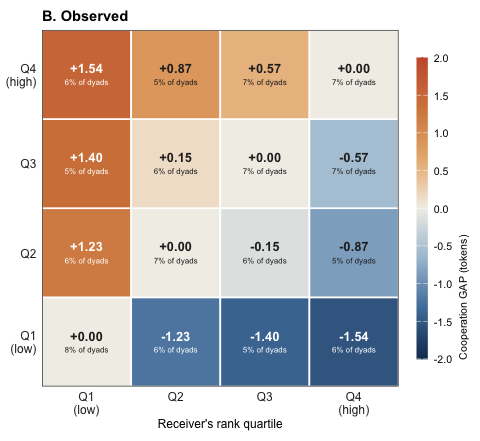

In [ ]:
quartile_panel("observed", "B. Observed", legend = TRUE)

Both heatmaps, as in the SI:

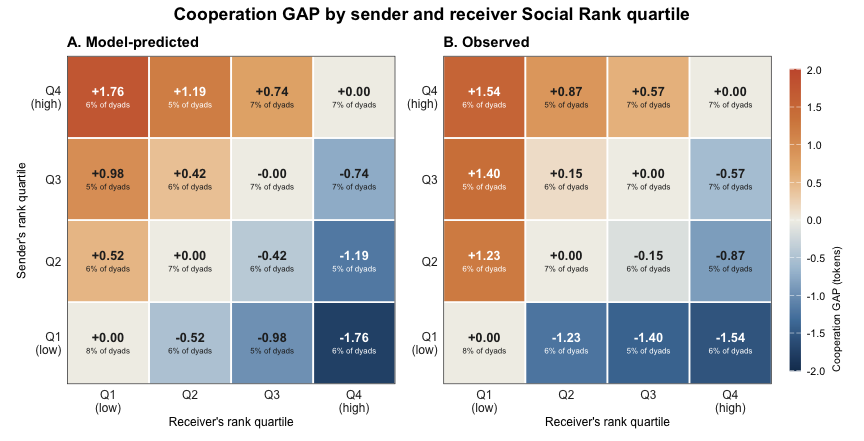

In [ ]:
figure_s24 <- (quartile_panel("predicted", "A. Model-predicted") |
               quartile_panel("observed", "B. Observed", legend = TRUE)) +
  plot_annotation(title = "Cooperation GAP by sender and receiver Social Rank quartile",
                  theme = theme(plot.title = element_text(face = "bold", hjust = 0.5)))
figure_s24

In [ ]:
save_table(regression_table(fe_all, terms = "rank_gap"),    "S7_table_s17_all")
save_table(regression_table(fe_non, terms = "rank_gap"),    "S7_table_s18_non_friends")
save_table(regression_table(fe_mutual, terms = "rank_gap"), "S7_table_s19_mutual")
save_table(regression_table(fe_pooled, terms = c("rank_gap", "mutual", "rank_gap:mutual")), "S7_table_s20_pooled")
save_table(implied_mutual_slope, "S7_table_s20_implied_mutual_slope")
save_table(table_s21, "S7_table_s21_asymmetric_support")
save_table(regression_table(fe_low_to_high, terms = "rank_gap"), "S7_table_s22_low_to_high")
save_table(regression_table(fe_high_to_low, terms = "rank_gap"), "S7_table_s22_high_to_low")
save_table(table_s23, "S7_table_s23_direction_contrast")
save_table(table_s24, "S7_table_s24_magnitudes")
save_table(quartile_cells, "S7_quartile_cells")
save_si_figure(figure_s22, "S7_figure_s22_gap_histogram", 8, 3.6)
save_si_figure(figure_s23, "S7_figure_s23_predicted", 7.5, 4.2)
save_si_figure(figure_s24, "S7_figure_s24_quartiles", 9, 4.6)